rumz
# Notebook for processing bubbles in Ice Cores
### July 25
#### V. 2.1
- updated to use adaptive thresholding for bubble detection

This notebook processes hyperspectral images of ice and extracts information in regards to the bubbles.
To run:
- ensure datasetPath points to the correct directory file
- Insert DataID for whichever core to be run
- Run all

In [1]:
# Importing Python Libraries
import warnings
import sys
import os
import matplotlib.pyplot as plt

# Add the processing folder to the Python path
processing_path = os.path.abspath(os.path.join('..', 'processing'))
if processing_path not in sys.path:
    sys.path.append(processing_path)

#Importing Python Libraries and Packages
import pandas as pd
import numpy as np
import set_icespec_path as tool
import set_bubbles_path as tool2
icespec_code_path=tool.add_icespec_code_dir()
bubble_code_path=tool2.add_bubble_code_dir()
tool.add_icespec_code_dir()
tool2.add_bubble_code_dir()
from icespec import icespec_process2_module as processice
from bubbles import bubbles_process_module as processbubbles
from icespec import savePNG
from icespec import ageConversion

In [2]:
DataID = "HSIUM-40" #insert DataID from excel file inside quotation marks

NumID = int(DataID.split('-')[-1])

if NumID > 228:
    datasetPath = '/data/icecores/HSI_Jan2024.csv' #path to csv file on computer or server
else:
    datasetPath = '/data/icecores/HSI_2024.csv'

outputDir = '/data/icecores/Output' #png output path
SCRIPT_ID = "BubblesNB"

Debug = False

In [3]:
dataPath, top_depth, bottom_depth, core_length, save_path, px_dims, metadata = processice.getDataPath(datasetPath, DataID, outputDir)

outputPath = processice.make_dir(save_path, SCRIPT_ID, metadata)
print("Output Path: ", outputPath)

%matplotlib ipympl
data_nparr, w_ref, d_ref, fwhm = processice.getEnviData(dataPath)

Core:  ALHIC 2302
Section:  46 Sec 56
Lighting: Top light - 50%, Bottom Light - 100%
Exposure:  4
Top Depth:  39.5
Bottom Depth:  40.41
Length =  0.9099999999999966
Dimensions:  1350, 6000, 100, 900
Output Path:  /data/icecores/Output/AN/ALHIC/ALHIC2302/ALHIC2302-46/2025-08-01_105815


In [4]:
segment_boundaries, pixels_per_cm = processbubbles.get_segments(data_nparr, top_depth, bottom_depth, end_px=px_dims[1])
print("pixels per cm: ", pixels_per_cm)

pixels per cm:  52.74725274725294


In [5]:
#dataSize = [1500, 6600, 200, 900] #fill in based on interactive plot
dataSize = px_dims
stdSize = [530, 820, 200, 900] #standard sizing

/home/rumz/anaconda3/envs/HSenv/lib/python3.12/site-packages/spectral/graphics/spypylab.py:796: UserWarning: Failed to create RectangleSelector object. Interactive pixel class labeling will be unavailable.
  warnings.warn(msg)


Shape After:  (4650, 700, 106)


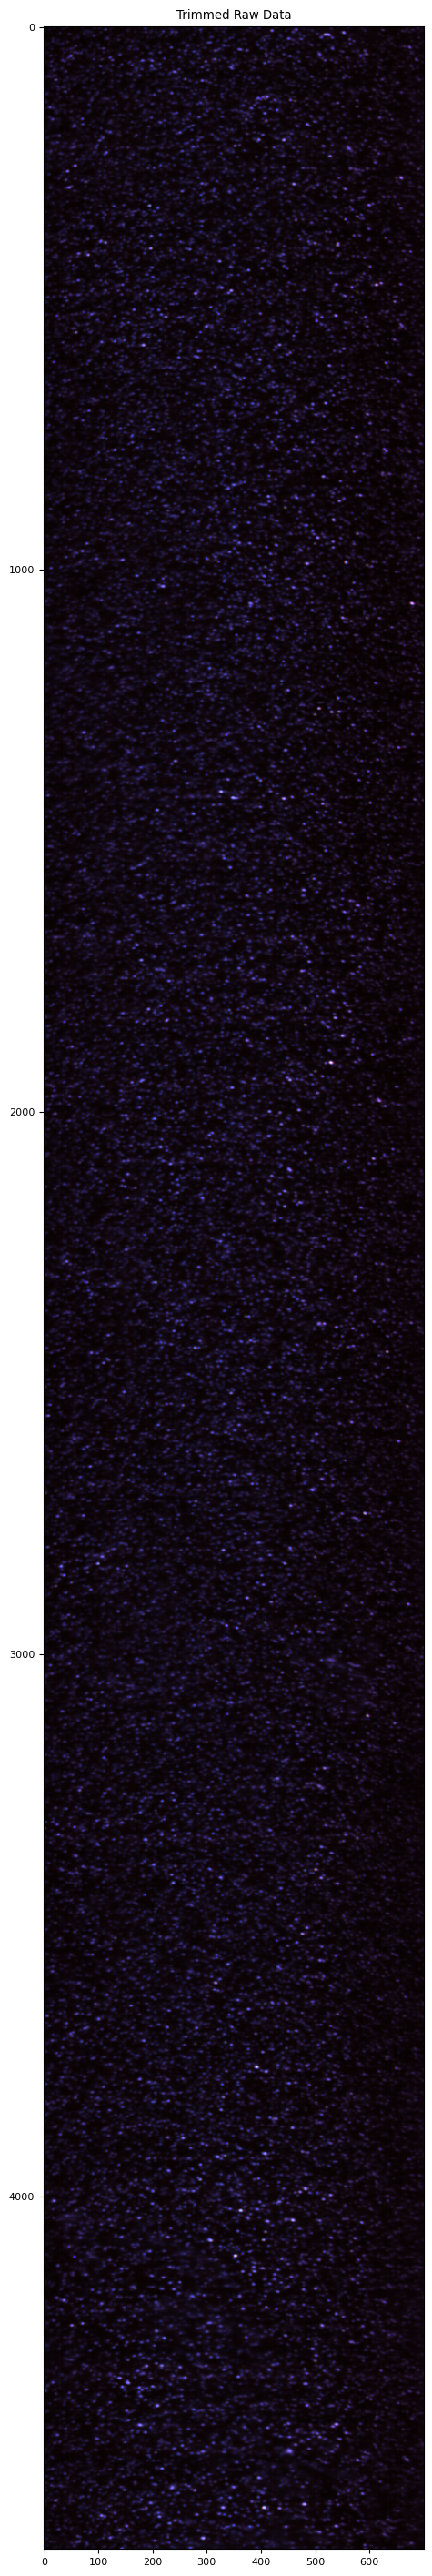

In [6]:
%matplotlib inline
trimmedData = processice.trim(data_nparr, w_ref, d_ref, dataSize, stdSize, Debug=Debug) #return arr of 3 trimmed
correctedData = processice.reflectance(trimmedData, Debug)
filtered_img, fwhm = processice.remove_bands(correctedData, trimmedData[1], fwhm)

In [7]:
bubbles_only, bubble_masks, bubble_only_2d, bubble_channel_map = processbubbles.get_bubbles(filtered_img, fwhm, clean=True)

ValueError: 1 columns passed, passed data had 7 columns

In [ ]:
df_map = pd.DataFrame([
    {"Bubble_ID": b_id, "Bands": bands, "Num_Bands": len(bands)}
    for b_id, bands in bubble_channel_map.items()
])

print(df_map)

In [ ]:
from skimage.color import label2rgb

# Compute band count per bubble
band_count_map = np.zeros_like(bubble_only_2d, dtype=int)
for b_id, bands in bubble_channel_map.items():
    band_count_map[bubble_only_2d == b_id] = len(bands)

colored = label2rgb(band_count_map, image=filtered_img[:, :, 0], bg_label=0, kind='overlay')
plt.imshow(colored)
plt.title("Bubbles Colored by Number of Bands Detected")
plt.axis("off")
plt.show()

In [ ]:
# # Bubbles only detected in 1 band (potential noise)
# print("Single-band bubbles:", df_map[df_map["Num_Bands"] == 1])

# # Bubbles detected in ALL bands (strong signal)
# print("All-band bubbles:", df_map[df_map["Num_Bands"] == filtered_img.shape[2]])

In [ ]:
analyzed_bubbles, bubble_df, bubble_area_ratio = processbubbles.analyze_bubbles(bubble_only_2d, dataSize[0], pixels_per_cm, top_depth, min_size=10, Debug=Debug, Save=False, savepath=outputPath)
readme_path = outputPath / "README.md"
with readme_path.open("a") as f:
    f.write(f"\n###  Bubble Area Ratio: {bubble_area_ratio}%\n")
stats_df = processbubbles.get_stats(bubble_df, pixels_per_cm)

DSName = outputPath.parent.name
filename = f"{DSName}_bubbleData.csv"
bubble_df.to_csv(f"{outputPath}/{filename}", index=False)
readme_path = outputPath / "README.md"
with readme_path.open("a") as f:
    f.write(f"\n###  Output File: {filename}\n- {DSName}: CSV File of all detected bubbles and their properties\n")

DSName = outputPath.parent.name
filename = f"{DSName}_bubble_stats.csv"
stats_df.to_csv(f"{outputPath}/{filename}", index=False)
readme_path = outputPath / "README.md"
with readme_path.open("a") as f:
    f.write(f"\n###  Output File: {filename}\n- {DSName}: CSV File of Bubble stats across whole core section\n")